<!-- This is the beginning code to clean ebird for LA  -->

Note for future Oliver-- skip to filtered.path after loading packages and run from there

# **Part 1.** Cleaning Ebird Data 

Updated: 11.08.2026
Author: Oliver Nguyen


In [1]:

#Libraries needed
import pandas as pd
import geopandas as gpd
from datetime import datetime
from pathlib import Path
import numpy as np
import duckdb as duckdb

# Import rpy2 components
%pip install rpy2

import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, Formula
from rpy2.robjects.packages import importr
from rpy2.robjects.conversion import localconverter




c:\Users\einna\anaconda3\envs\sf_env\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


ImportError: cannot import name 'cascaded_union' from 'shapely.ops' (c:\Users\einna\anaconda3\envs\sf_env\Lib\site-packages\shapely\ops.py)

## Cleaning the Damn thing


1. Import checklists and observations
2. Save to Parquets and process in chunks 
    * Convert and process effort hours 
    * auk roll-up 
    * zero-filling
4. Filter efforts (observation hours, distance, number of observers)
5. Seperate into stationary and travelling checklists
3. Keep only max observations of species per day 



In [2]:

# ============================================================================
# Import R packages
# ============================================================================

print("Loading R packages...")

# Import R packages
base = importr('base')
utils = importr('utils')
auk = importr('auk')
lubridate = importr('lubridate')
dplyr = importr('dplyr')
sf = importr('sf')

# Resolve namespace conflicts in R
ro.r('select <- dplyr::select')
ro.r('filter <- dplyr::filter')
print("R packages loaded successfully!")


Loading R packages...


PackageNotInstalledError: The R package "auk" is not installed.

In [3]:

# ============================================================================
# eBird Data Processing 
# ============================================================================

import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from pathlib import Path
import pandas as pd



In [4]:

# ============================================================================
# 3. FAST PROCESSING WITH auk PACKAGE
# ============================================================================

ro.r(r'''
    library(auk)
    library(dplyr)
    library(lubridate)
    library(sf)
    library(data.table)
    
    # Resolve namespace conflicts
    select <- dplyr::select
    filter <- dplyr::filter
    
    n_cores <- parallel::detectCores() - 1
    setDTthreads(n_cores)
    
    cat("Using", n_cores, "cores\n")
    

''')


R callback write-console: data.table 1.17.8 using 12 threads (see ?getDTthreads).    
R callback write-console: Latest news: r-datatable.com
  
R callback write-console: 
Attaching package: 'data.table'

  
R callback write-console: The following objects are masked from 'package:dplyr':

    between, first, last

  
R callback write-console: The following objects are masked from 'package:lubridate':

    hour, isoweek, mday, minute, month, quarter, second, wday, week,
    yday, year

  


Using 23 cores


In [ ]:
# This takes about 103 mins
# ============================================================================
# 1. Process eBird data in monthly chunks with stationary filters
# ============================================================================

ro.r(r'''
library(auk)
library(dplyr)
library(lubridate)
library(sf)
library(janitor)  # For clean_names()

# Resolve namespace conflicts
select <- dplyr::select
filter <- dplyr::filter

# Set parameters
rerun <- TRUE  # Set to TRUE to rerun filtering
start_year <- 2010
end_year <- 2025
end_month <- 12

# Set input file paths (your original eBird files)
f_ebd_input <- "D:/Chapter1_SF_redlining_Rprj/ebd_US-CA-075_201001_202512_smp_relMar-2026/ebd_US-CA-075_201001_202512_smp_relMar-2026.txt"
f_sed_input <- "D:/Chapter1_SF_redlining_Rprj/ebd_US-CA-075_201001_202512_smp_relMar-2026/ebd_US-CA-075_201001_202512_smp_relMar-2026_sampling."



# Create output directory if it doesn't exist
dir.create("D:/Chapter1_SF_redlining_Rprj/data/ebd_US-SF_chunked", showWarnings = FALSE, recursive = TRUE)

# ========================================================================
# STEP A: Filter data into monthly chunks
# ========================================================================

if (rerun) {
  cat("\n================================================================================\n")
  cat("FILTERING DATA INTO MONTHLY CHUNKS (STATIONARY ONLY)\n")
  cat("================================================================================\n")
  
  list_years <- seq(start_year, end_year)
  total_months <- 0
  
  # Count total months to process
  for (list_year in list_years) {
    for (list_month in seq(1, 12)) {
      if (list_year < end_year | (list_year == end_year & list_month <= end_month)) {
        total_months <- total_months + 1
      }
    }
  }
  
  cat(sprintf("\nProcessing %d months from %d-%02d to %d-%02d\n", 
              total_months, start_year, 1, end_year, end_month))
  
  current_month <- 0
  
  # Function to convert time to decimal hours (define once outside loop)
  time_to_decimal <- function(x) {
    x <- hms(x, quiet = TRUE)
    hour(x) + minute(x) / 60 + second(x) / 3600
  }
  
  for (list_year in list_years) {
    for (list_month in seq(1, 12)) {
      if (list_year < end_year | (list_year == end_year & list_month <= end_month)) {
        
        current_month <- current_month + 1
        
        # Create date range to use in auk filter
        start_date <- make_date(year = list_year, month = list_month, day = 1L)
        end_date <- ceiling_date(start_date, unit = "month") - 1
        
        cat(sprintf("\n[%d/%d] Processing %s to %s...\n", 
                    current_month, total_months, start_date, end_date))
        
        # Create output filenames based on month and year
        file_ebd <- file.path('D:/Chapter1_SF_redlining_Rprj/data/ebd_US-SF_chunked', 
                              paste0('ebd_filtered_SF_', list_year, '_', 
                                     sprintf("%02d", list_month), '.txt'))
        file_sampling <- file.path('D:/Chapter1_SF_redlining_Rprj/data/ebd_US-SF_chunked', 
                                   paste0('sampling_filtered_SF_', list_year, '_', 
                                          sprintf("%02d", list_month), '.txt'))
        
        # Filter data using auk
        cat("  Filtering data...\n")
        auk_ebd(f_ebd_input, file_sampling = f_sed_input) %>%
          auk_date(date = c(start_date, end_date)) %>%
          auk_complete() %>%  # Only complete checklists
          auk_filter(file = file_ebd, 
                     file_sampling = file_sampling,
                     overwrite = TRUE)
     
        # ======================================================
        # STEP B: Read the filtered data with zero-fill
        # ======================================================
        cat("  Reading filtered data...\n")
        ebd_zf <- auk_zerofill(x = file_ebd, 
                               sampling_events = file_sampling, 
                               collapse = TRUE)
        
        cat(sprintf("    Observations before filtering: %s\n", 
                    format(nrow(ebd_zf), big.mark = ",")))
        
        # Standardize column names to lowercase with underscores
        cat("  Standardizing column names...\n")
        ebd_zf <- ebd_zf %>%
          clean_names(case = "snake")
        
        cat(sprintf("    Column names cleaned (first 5): %s\n", 
                    paste(head(names(ebd_zf), 5), collapse = ", ")))
     
        # ====================================
        # STEP C: Clean up variables, process, and FILTER
        # ====================================
        cat("  Processing variables and applying filters...\n")
        
        zf <- ebd_zf %>%
          mutate(
            # Calculate derived variables first
            observation_count = if_else(species_observed, 
                                       as.integer(observation_count), 
                                       0L),
            effort_distance_km = if_else(protocol_name == "Stationary", 
                                        0, effort_distance_km),
            effort_hours = duration_minutes / 60,
            effort_speed_kmph = if_else(effort_hours > 0,
                                       effort_distance_km / effort_hours,
                                       0),
            hours_of_day = time_to_decimal(time_observations_started),
            year = year(observation_date),
            day_of_year = yday(observation_date)
          ) %>%
          # Apply filters for stationary protocols with effort constraints
          filter(
            protocol_name == "Stationary",
            effort_hours <= 6,
            effort_distance_km <= 5,
            effort_speed_kmph <= 5,
            number_observers <= 10,
            
          )
        
        cat(sprintf("    Observations after filtering: %s\n", 
                    format(nrow(zf), big.mark = ",")))
        
        # Show filtering statistics
        if (nrow(ebd_zf) > 0) {
          pct_kept <- 100 * nrow(zf) / nrow(ebd_zf)
          cat(sprintf("    Kept: %.1f%% (removed %s observations)\n", 
                      pct_kept,
                      format(nrow(ebd_zf) - nrow(zf), big.mark = ",")))
        }
        
        # Only save if there's data
        if (nrow(zf) > 0) {
          # Save the processed data
          output_file <- file.path('D:/Chapter1_SF_redlining_Rprj/data/ebd_US-SF_chunked', 
                                  paste0('ebd_processed_stationary_SF_', list_year, '_', 
                                         sprintf("%02d", list_month), '.csv'))
          write.csv(zf, output_file, row.names = FALSE)
          
          cat(sprintf("  ✓ Processed and saved: %s\n", basename(output_file)))
        } else {
          cat("  ⚠ No observations passed filters, skipping save.\n")
        }
        
        # Clean up memory
        rm(ebd_zf, zf)
        gc(verbose = FALSE)
      }
    }
  }
  
  cat("\n✓ All monthly chunks filtered and processed successfully!\n")
  
  # ========================================================================
  # Summary of all processed files
  # ========================================================================
  cat("\n================================================================================\n")
  cat("SUMMARY\n")
  cat("================================================================================\n")
  
  processed_files <- list.files("D:/Chapter1_SF_redlining_Rprj/data/ebd_US-SF_chunked",
                                pattern = "^ebd_processed_stationary_SF_.*\\.csv$",
                                full.names = FALSE)
  
  cat(sprintf("\nTotal monthly files created: %d\n", length(processed_files)))
  cat("\nFilters applied:\n")
  cat("  - Protocol: Stationary only\n")
  cat("  - Effort hours: <= 6\n")
  cat("  - Effort distance: <= 5 km\n")
  cat("  - Effort speed: <= 5 km/h\n")
  cat("  - Number of observers: <= 10\n")
}
''')



FILTERING DATA INTO MONTHLY CHUNKS (STATIONARY ONLY)

Processing 192 months from 2010-01 to 2025-12

[1/192] Processing 2010-01-01 to 2010-01-31...
  Filtering data...
  Reading filtered data...
    Observations before filtering: 28,500
  Standardizing column names...
    Column names cleaned (first 5): checklist_id, last_edited_date, country, country_code, state
  Processing variables and applying filters...
    Observations after filtering: 3,750
    Kept: 13.2% (removed 24,750 observations)
  <U+2713> Processed and saved: ebd_processed_stationary_SF_2010_01.csv

[2/192] Processing 2010-02-01 to 2010-02-28...
  Filtering data...
  Reading filtered data...
    Observations before filtering: 19,728
  Standardizing column names...
    Column names cleaned (first 5): checklist_id, last_edited_date, country, country_code, state
  Processing variables and applying filters...
    Observations after filtering: 1,781
    Kept: 9.0% (removed 17,947 observations)
  <U+2713> Processed and saved

R callback write-console: In addition:   
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  


In [ ]:
# =======================================
# 2. Combine monthly files, add max observations, train/test split
# =======================================

import duckdb
import pandas as pd
import os

print("\n" + "="*80)
print("STEP 2: COMBINING MONTHLY FILES AND ADDING MAX OBSERVATIONS")
print("="*80 + "\n")

# Create a specific temp directory on D drive
temp_dir = "D:/Chapter1_LA_redlining/data/temp"
os.makedirs(temp_dir, exist_ok=True)

# Connect to DuckDB with temp directory configuration
con = duckdb.connect()
con.execute("SET preserve_insertion_order = false")
con.execute("SET threads = 1")
con.execute("PRAGMA max_temp_directory_size='300GiB'")
con.execute(f"SET temp_directory='{temp_dir}'")

# Get all monthly CSV files
monthly_pattern = "D:/Chapter1_SF_redlining_Rprj/data/ebd_US-SF_chunked/ebd_processed_stationary_SF_*.csv"

print("Reading monthly stationary files...")

# Get distinct years from the monthly files
years = con.execute(f"""
  SELECT DISTINCT YEAR(observation_date) as year 
  FROM read_csv_auto('{monthly_pattern}', 
                     union_by_name=true, 
                     ignore_errors=true,
                     nullstr='NA')
  ORDER BY year
""").fetchall()

years = [y[0] for y in years]
print(f"Processing years: {years}\n")

# ========================================================================
# Step 2a: Create train/test split
# ========================================================================
print("--- Creating train/test split ---")

first_year = years[0]
print(f"Creating table with year {first_year}...")
con.execute(f"""
  CREATE TABLE observations_split AS
  SELECT *, 
         CASE WHEN random() <= 0.8 THEN 'train' ELSE 'test' END as type
  FROM read_csv_auto('{monthly_pattern}', 
                     union_by_name=true, 
                     ignore_errors=true,
                     nullstr='NA')
  WHERE YEAR(observation_date) = {first_year}
""")

# Append remaining years
for year in years[1:]:
    print(f"Processing year {year}...")
    con.execute(f"""
      INSERT INTO observations_split
      SELECT *, 
             CASE WHEN random() <= 0.8 THEN 'train' ELSE 'test' END as type
      FROM read_csv_auto('{monthly_pattern}', 
                         union_by_name=true, 
                         ignore_errors=true,
                         nullstr='NA')
      WHERE YEAR(observation_date) = {year}
    """)

print("✓ Train/test split complete!\n")

# ========================================================================
# Step 2b: Add max_observations per species per day
# ========================================================================
print("--- Adding max_observations column ---")

years = con.execute("""
  SELECT DISTINCT YEAR(observation_date) as year 
  FROM observations_split 
  ORDER BY year
""").fetchall()
years = [y[0] for y in years]

first_year = years[0]
print(f"Processing year {first_year}...")
con.execute(f"""
  CREATE TABLE observations_with_max AS
  SELECT *,
         MAX(COALESCE(TRY_CAST(observation_count AS INTEGER), 0)) OVER (
           PARTITION BY scientific_name, observation_date
         ) as max_observations
  FROM observations_split
  WHERE YEAR(observation_date) = {first_year}
""")

for year in years[1:]:
    print(f"Processing year {year}...")
    con.execute(f"""
      INSERT INTO observations_with_max
      SELECT *,
             MAX(COALESCE(TRY_CAST(observation_count AS INTEGER), 0)) OVER (
               PARTITION BY scientific_name, observation_date
             ) as max_observations
      FROM observations_split
      WHERE YEAR(observation_date) = {year}
    """)

print("✓ Max observations calculated!\n")

# ========================================================================
# Step 2c: Keep only max observations (filter out non-max)
# ========================================================================
print("--- Keeping only maximum observations ---")

# Process in smaller chunks to avoid temp space issues
years = con.execute("""
  SELECT DISTINCT YEAR(observation_date) as year 
  FROM observations_with_max 
  ORDER BY year
""").fetchall()
years = [y[0] for y in years]

first_year = years[0]
print(f"Filtering year {first_year}...")
con.execute(f"""
  CREATE TABLE observations_max_only AS
  SELECT *
  FROM observations_with_max
  WHERE YEAR(observation_date) = {first_year}
    AND COALESCE(TRY_CAST(observation_count AS INTEGER), 0) = max_observations
""")

for year in years[1:]:
    print(f"Filtering year {year}...")
    con.execute(f"""
      INSERT INTO observations_max_only
      SELECT *
      FROM observations_with_max
      WHERE YEAR(observation_date) = {year}
        AND COALESCE(TRY_CAST(observation_count AS INTEGER), 0) = max_observations
    """)

print("✓ Filtered to max observations only!\n")

# Check results
result = con.execute("""
    SELECT 
        COUNT(*) as total_rows,
        MIN(observation_date) as min_date,
        MAX(observation_date) as max_date,
        COUNT(DISTINCT scientific_name) as n_species,
        COUNT(DISTINCT sampling_event_identifier) as n_checklists
    FROM observations_max_only
""").df()

print("\nAfter keeping only max observations:")
print(result)

# Train/test breakdown
split_summary = con.execute("""
    SELECT 
        type,
        COUNT(*) as n_observations,
        COUNT(DISTINCT sampling_event_identifier) as n_checklists,
        COUNT(DISTINCT scientific_name) as n_species,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) as pct
    FROM observations_max_only
    GROUP BY type
""").df()
print("\nTrain/Test Split:")
print(split_summary)

# Check data quality
print("\nData Quality Check:")
quality_check = con.execute("""
    SELECT 
        COUNT(*) as total,
        SUM(CASE WHEN observation_count IS NULL THEN 1 ELSE 0 END) as null_counts,
        SUM(CASE WHEN max_observations = 0 THEN 1 ELSE 0 END) as zero_max,
        MIN(max_observations) as min_max,
        MAX(max_observations) as max_max,
        AVG(max_observations) as avg_max
    FROM observations_max_only
""").df()
print(quality_check)

# Save intermediate result
print("\nSaving intermediate file (before spatial filter)...")
con.execute("""
  COPY observations_max_only 
  TO 'D:/Chapter1_SF_redlining_Rprj/data/output/observations_max_prespatial.parquet'
  (FORMAT PARQUET)
""")
print("✓ Saved: observations_max_prespatial.parquet")

print("\n" + "="*80)
print("STEP 2 COMPLETE!")
print("="*80 + "\n")

con.close()

# Clean up temp directory if desired
# import shutil
# shutil.rmtree(temp_dir, ignore_errors=True)


STEP 2: COMBINING MONTHLY FILES AND ADDING MAX OBSERVATIONS

Reading monthly stationary files...
Processing years: [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

--- Creating train/test split ---
Creating table with year 2010...
Processing year 2011...
Processing year 2012...
Processing year 2013...
Processing year 2014...
Processing year 2015...
Processing year 2016...
Processing year 2017...
Processing year 2018...
Processing year 2019...
Processing year 2020...
Processing year 2021...
Processing year 2022...
Processing year 2023...
Processing year 2024...
Processing year 2025...
✓ Train/test split complete!

--- Adding max_observations column ---
Processing year 2010...
Processing year 2011...
Processing year 2012...
Processing year 2013...
Processing year 2014...
Processing year 2015...
Processing year 2016...
Processing year 2017...
Processing year 2018...
Processing year 2019...
Processing year 2020...
Processing year 2021...
Pr

IOException: IO Error: Cannot open file "D:/Chapter1_SF_redlining_Rprj/data/output/observations_max_prespatial.parquet": The system cannot find the path specified.


In [8]:
# Save intermediate result
print("\nSaving intermediate file (before spatial filter)...")
con.execute("""
  COPY observations_max_only 
  TO 'D:/Chapter1_SF_redlining_Rprj/data/output/observations_max_prespatial.parquet'
  (FORMAT PARQUET)
""")
print("✓ Saved: observations_max_prespatial.parquet")

print("\n" + "="*80)
print("STEP 2 COMPLETE!")
print("="*80 + "\n")

con.close()


Saving intermediate file (before spatial filter)...
✓ Saved: observations_max_prespatial.parquet

STEP 2 COMPLETE!



In [ ]:

# Save intermediate result
print("\nSaving intermediate file (before spatial filter)...")
con.execute("""
  COPY observations_max_only 
  TO 'D:/Chapter1_SF_redlining_Rprj/data/output/observations_max_prespatial.parquet'
  (FORMAT PARQUET)
""")
print("✓ Saved: observations_max_prespatial.parquet")

print("\n" + "="*80)
print("STEP 2 COMPLETE!")
print("="*80 + "\n")

con.close()

# Clean up temp directory if desired
# import shutil
# shutil.rmtree(temp_dir, ignore_errors=True)

Stop here and move to Part 2: LA_holc_join_12.13.25.ipynb 

We should have something to join to the HOLC now 


In [ ]:
# ro.r(r'''
# # ========================================================================
# # STEP 4: Create spatial object and save final results
# # ========================================================================

# cat("\n================================================================================\n")
# cat("CREATING SPATIAL OBJECT AND SAVING\n")
# cat("================================================================================\n")

# cat("\nCreating spatial object...\n")
# checklists_la <- checklists_final %>%
#   select(sampling_event_identifier, latitude, longitude) %>%
#   st_as_sf(coords = c("longitude", "latitude"), crs = 4326)
# cat("✓ Spatial object created\n")

# cat("\nSaving final results...\n")

# cat("  Saving checklists CSV...\n")
# write.csv(checklists_final, 
#           "D:/Chapter1_LA_redlining/data/LAchecklists_filtered_1.16.25.csv", 
#           row.names = FALSE)
# cat("  ✓ Checklists saved\n")

# cat("  Saving observations CSV...\n")
# write.csv(observations_final, 
#           "D:/Chapter1_LA_redlining/data/LAobservations_filtered_1.16.25.csv", 
#           row.names = FALSE)
# cat("  ✓ Observations saved\n")

# cat("  Saving spatial file...\n")
# st_write(checklists_la, 
#          "D:/Chapter1_LA_redlining/data/LAchecklists_1.16.25.gpkg", 
#          delete_dsn = TRUE, 
#          quiet = TRUE)
# cat("  ✓ Spatial file saved\n")

# # ========================================================================
# # SUMMARY
# # ========================================================================

# cat("\n================================================================================\n")
# cat("PROCESSING COMPLETE!\n")
# cat("================================================================================\n")
# cat(sprintf("Final checklists:   %s\n", format(nrow(checklists_final), big.mark = ",")))
# cat(sprintf("Final observations: %s\n", format(nrow(observations_final), big.mark = ",")))
# cat("\nFiles saved to D:/Chapter1_LA_redlining/data/:\n")
# cat("  - LAchecklists_filtered_1.16.25.csv\n")
# cat("  - LAobservations_filtered_1.16.25.csv\n")
# cat("  - LAchecklists_1.16.25.gpkg\n")

# cat("\nMonthly chunks saved to:\n")
# cat("  - D:/Chapter1_LA_redlining/data/ebd_US-LA_chunked/\n")

#      ''')


CREATING SPATIAL OBJECT AND SAVING

Creating spatial object...
<U+2713> Spatial object created

Saving final results...
  Saving checklists CSV...
  <U+2713> Checklists saved
  Saving observations CSV...
  <U+2713> Observations saved
  Saving spatial file...
  <U+2713> Spatial file saved

PROCESSING COMPLETE!
Final checklists:   545,160
Final observations: 9,613,879

Files saved to D:/Chapter1_LA_redlining/data/:
  - LAchecklists_filtered_1.16.25.csv
  - LAobservations_filtered_1.16.25.csv
  - LAchecklists_1.16.25.gpkg

Monthly chunks saved to:
  - D:/Chapter1_LA_redlining/data/ebd_US-LA_chunked/


Now we load and grab only ones that fall within LA boundary

R callback write-console: Retrieving data for the year 2024
  


Loading LA County boundary...


R callback write-console: Using FIPS code '06' for state 'CA'
  


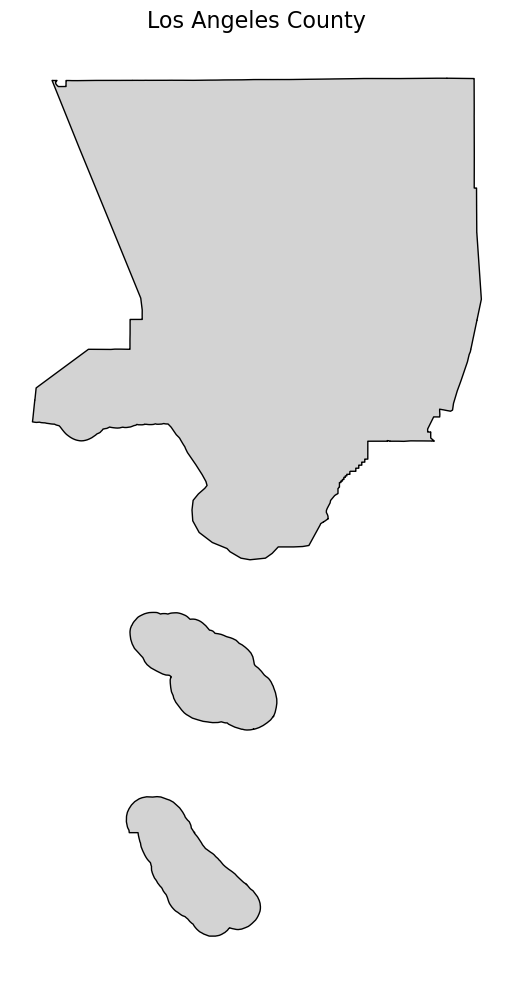

✓ LA County loaded: 1 polygon(s)
Getting census tracts (this may take a few minutes)...
[1] "Getting shapefile for tracts in CA"


R callback write-console: Using FIPS code '06' for state 'CA'
  
R callback write-console: Using FIPS code '037' for 'Los Angeles County'
  


[1] "Fetching water boundaries for CA"


R callback write-console: Using FIPS code '06' for state 'CA'
  


[1] "Subtracting water areas from census tract areas"


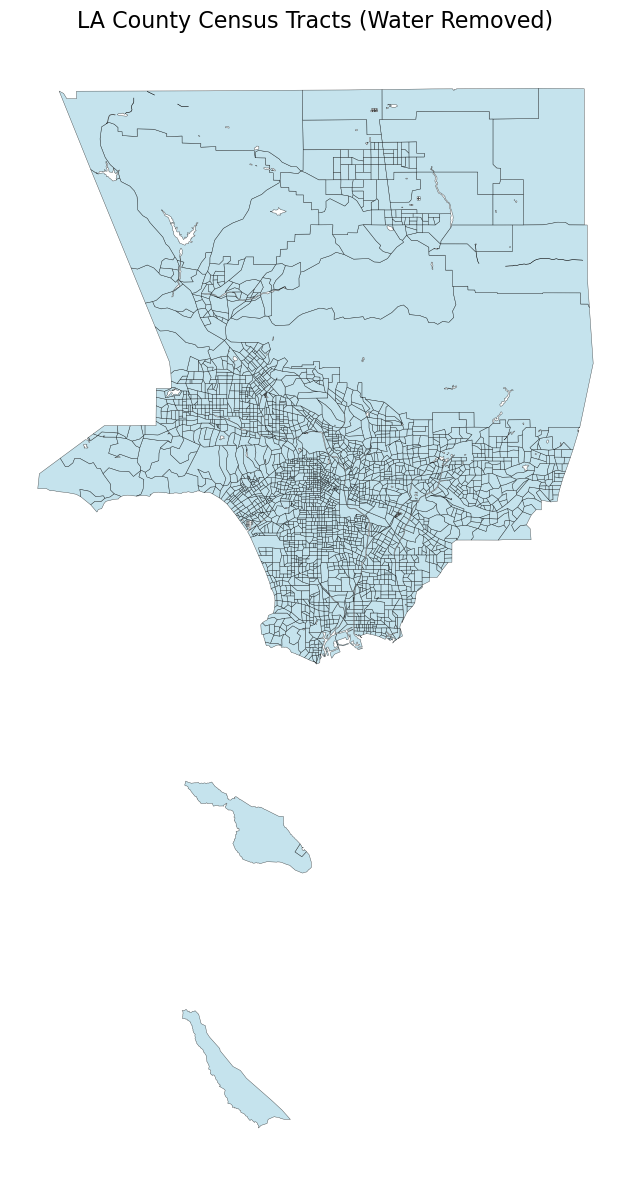

✓ Loaded 2492 census tracts


In [19]:

import matplotlib.pyplot as plt 

output_dir = "D:/Chapter1_LA_redlining/data/output"

# %% [markdown]
# ## Load LA County Boundary

# %%
print("Loading LA County boundary...")

ro.r(f'''
    library(tigris)
    library(sf)
    library(dplyr)
    
    # Set projection for LA
    map_proj <- st_crs(26911)  # UTM Zone 11N
    
    # Load California counties
    CA_county <- counties("CA")
    
    # Subset for LA county
    LA_county <- CA_county[CA_county$NAME == "Los Angeles",]
    
    # Save for later use
    st_write(LA_county, "{output_dir}/LA_county.shp", delete_dsn = TRUE, quiet = TRUE)
''')

# Load into Python
LA_county = gpd.read_file(f"{output_dir}/LA_county.shp")

# Plot
fig, ax = plt.subplots(figsize=(10, 10))
LA_county.plot(ax=ax, edgecolor='black', facecolor='lightgray')
ax.set_title("Los Angeles County", fontsize=16)
ax.set_axis_off()
plt.tight_layout()
plt.show()

print(f"✓ LA County loaded: {len(LA_county)} polygon(s)")

# %% [markdown]
# ## Get Census Tracts with Water Removed

# %%
print("Getting census tracts (this may take a few minutes)...")

ro.r(f'''
    library(tigris)
    library(sf)
    library(rmapshaper)
    library(purrr)
    
    get_tracts <- function(state_abbr, county_name, year=NULL, 
                          refresh=FALSE, remove_water=TRUE){{
        
        print(paste0("Getting shapefile for tracts in ", state_abbr))
        state_tracts <- tracts(cb = TRUE, 
                              year = year, 
                              class="sf", 
                              state=state_abbr,
                              county=county_name,
                              refresh=refresh) %>% 
            st_transform(., crs=4326) %>% 
            st_make_valid()
        
        Sys.sleep(1)
        
        if(!remove_water){{
            return(state_tracts)
        }}
        
        print(paste0("Fetching water boundaries for ", state_abbr))
        county_codes <- unique(state_tracts$COUNTYFP)
        
        water_area <- map_dfr(
            county_codes,
            ~ area_water(state_abbr, 
                        county = ., 
                        year = year,
                        refresh = refresh,
                        class = "sf") %>% 
                select("geometry") %>% 
                st_transform(., crs=4326) %>% 
                st_make_valid()
        )
        
        print("Subtracting water areas from census tract areas")
        state_tracts_sans_water <- ms_erase(
            ms_simplify(state_tracts),
            ms_simplify(water_area), 
            remove_slivers=TRUE,
            sys=FALSE
        )
        
        Sys.sleep(1)
        return(state_tracts_sans_water)
    }}
    
    # Get tracts with water removed
    la_tracts <- get_tracts("CA", "Los Angeles", year=2020, remove_water=TRUE)
    
    # Save
    st_write(la_tracts, "{output_dir}/la_tracts.shp", delete_dsn=TRUE, quiet=TRUE)
''')

# Load into Python
la_tracts = gpd.read_file(f"{output_dir}/la_tracts.shp")

# Plot
fig, ax = plt.subplots(figsize=(12, 12))
la_tracts.plot(ax=ax, edgecolor='black', facecolor='lightblue', linewidth=0.3, alpha=0.7)
ax.set_title("LA County Census Tracts (Water Removed)", fontsize=16)
ax.set_axis_off()
plt.tight_layout()
plt.show()

print(f"✓ Loaded {len(la_tracts)} census tracts")


Creating LA boundary and clipping checklists...


<Axes: >

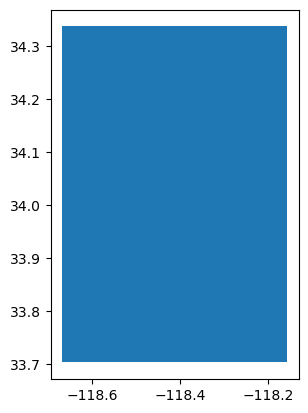

In [33]:

# %% [markdown]
# ## Create LA Boundary Box and Clip Checklists
import matplotlib.pyplot as plt 
# %%
print("Creating LA boundary and clipping checklists...")

# Create boundary box
bbox_coords = (-118.6682, 33.7037, -118.1553, 34.3373)  # W, S, E, N for LA
from shapely.geometry import box
la_bound_geom = box(*bbox_coords)
la_bound = gpd.GeoDataFrame({'geometry': [la_bound_geom]}, crs='EPSG:4326')

# Save boundary
la_bound.to_file(f"{output_dir}/la_boundary.shp")
la_bound.plot()

In [67]:
ro.r(r'''
     map_prj <- st_crs(LA_county)
     print(map_prj)
     print(colnames(observations_2))
     ''')

Coordinate Reference System:
  User input: NAD83 
  wkt:
GEOGCRS["NAD83",
    DATUM["North American Datum 1983",
        ELLIPSOID["GRS 1980",6378137,298.257222101,
            LENGTHUNIT["metre",1]]],
    PRIMEM["Greenwich",0,
        ANGLEUNIT["degree",0.0174532925199433]],
    CS[ellipsoidal,2],
        AXIS["latitude",north,
            ORDER[1],
            ANGLEUNIT["degree",0.0174532925199433]],
        AXIS["longitude",east,
            ORDER[2],
            ANGLEUNIT["degree",0.0174532925199433]],
    ID["EPSG",4269]]
 [1] "checklist_id"              "global_unique_identifier" 
 [3] "last_edited_date"          "taxonomic_order"          
 [5] "category"                  "taxon_concept_id"         
 [7] "common_name"               "scientific_name"          
 [9] "exotic_code"               "observation_count"        
[11] "breeding_code"             "breeding_category"        
[13] "behavior_code"             "age_sex"                  
[15] "country"                   "countr

In [ ]:
#This part is to briefly look at our data sets
#free up some space 

ro.r(f'''
breaks <- seq(0, 24)
labels <- breaks[-length(breaks)] + diff(breaks) / 2
checklists_time <- checklists |> 
  mutate(hour_bins = cut(hours_of_day, 
                         breaks = breaks, 
                         labels = labels,
                         include.lowest = TRUE),
         hour_bins = as.numeric(as.character(hour_bins))) |> 
  group_by(hour_bins) |> 
  summarise(n_checklists = n(),
            n_detected = sum(species_observed),
            det_freq = mean(species_observed))
''')

In [ ]:

ro.r(r'''
# Get top 20 species by total observation count
top_species <- zf_filtered %>%
  group_by(scientific_name) %>%
  summarize(total_count = sum(observation_count), na.rm = TRUE) %>%
  arrange(desc(total_count)) %>%
  head(20) %>%
  pull(scientific_name)

top_species


# Plot only those top species
zf_filtered %>%
  filter(scientific_name %in% top_species) %>%
  ggplot(aes(x = observation_date, y = scientific_name)) +
  geom_tile() +
  scale_fill_viridis_c(name = "Year", option = "plasma") +
  labs(
    title = "Top 20 Bird Species Observations Over Time",
    x = "Date",
    y = "Species",
    fill = "Observation Count"
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.text.y = element_text(size = 10)
  )

#Get species sighted per day

top_species <- zf_filtered %>%
  group_by(observation_date) %>%
  summarize(total_count = count(unique(scientific_name)), na.rm = TRUE) %>%
  arrange(desc(total_count)) %>%
  head(20) %>%
  pull(scientific_name)

    '''
)



#Now let's look at Checklist variation 
ro.r(f'''
# summarize data by hour long bins
breaks <- seq(0, 6)
labels <- breaks[-length(breaks)] + diff(breaks) / 2
checklists_duration <- checklists |> 
  mutate(duration_bins = cut(effort_hours, 
                             breaks = breaks, 
                             labels = labels,
                             include.lowest = TRUE),
         duration_bins = as.numeric(as.character(duration_bins))) |> 
  group_by(duration_bins) |> 
  summarise(n_checklists = n(),
            n_detected = sum(species_observed),
            det_freq = mean(species_observed))

# histogram
g_duration_hist <- ggplot(checklists_duration) +
  aes(x = duration_bins, y = n_checklists) +
  geom_segment(aes(xend = duration_bins, y = 0, yend = n_checklists),
               color = "grey50") +
  geom_point() +
  scale_x_continuous(breaks = breaks) +
  scale_y_continuous(labels = scales::comma) +
  labs(x = "Checklist duration [hours]",
       y = "# checklists",
       title = "Distribution of checklist durations")

# frequency of detection
g_duration_freq <- ggplot(checklists_duration |> filter(n_checklists > 100)) +
  aes(x = duration_bins, y = det_freq) +
  geom_line() +
  geom_point() +
  scale_x_continuous(breaks = breaks) +
  scale_y_continuous(labels = scales::percent) +
  labs(x = "Checklist duration [hours]",
       y = "% checklists with detections",
       title = "Detection frequency")

# combine
grid.arrange(g_duration_hist, g_duration_freq)

''')

